# Bat speed vs. Hitting reseult

 - Sometimes, hitters might swing slightly harder on some pitcher for more power, or swing slightly lighter for contact.
 - Does swinging harder always gets a better result?
 - Who should swing harder, who should not?

Method:
 - Using pybaseball to pull all the pitch data from Statcast. 
 - For each hitter, remove the slowest 10% of swings, and then analyze the best fit between bat speed and run value.
 - Predict change in run value per 100 swings when bat speed is 2 mph higher, with a 95% confidence interval. 


This demo can be used as a template for testing any players. 




In [4]:
# Imports and setup

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("../src")

import swing_gain as sg

from scipy.stats import linregress, t

from matplotlib.patches import Patch

from pathlib import Path

from pybaseball import statcast, playerid_lookup, playerid_reverse_lookup




The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Statcast season and date range

This demo uses the 2025 season as an example. 

In [15]:
SEASON = 2025
statcast_df = sg.load_statcast(SEASON)

print(statcast_df.shape)
statcast_df.head()

(712528, 119)


,pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,...,batter_days_until_next_game,api_break_z_with_gravity,api_break_x_arm,api_break_x_batter_in,arm_angle,attack_angle,attack_direction,swing_path_tilt,intercept_ball_minus_batter_pos_x_inches,intercept_ball_minus_batter_pos_y_inches
2007,FF,2025-09-28,95.7,-2.15,5.21,"Weissert, Greg",678009,669711,field_out,hit_into_play,...,2,1.56,0.71,-0.71,20.9,5.991833,-1.319512,28.782516,41.559201,30.599805
2065,FF,2025-09-28,95.1,-1.91,5.1,"Weissert, Greg",668670,669711,strikeout,called_strike,...,9,1.59,0.93,0.93,20.5,<NA>,<NA>,<NA>,<NA>,<NA>
2142,FF,2025-09-28,95.4,-1.99,5.22,"Weissert, Greg",668670,669711,NaN,foul,...,9,1.36,0.85,0.85,22.9,2.871131,31.805044,22.266527,37.478847,15.582717
2260,SL,2025-09-28,84.8,-2.33,4.72,"Weissert, Greg",668670,669711,NaN,swinging_strike,...,9,2.55,-0.32,-0.32,12.3,13.78541,4.08139,32.414181,38.011685,27.083341
2347,SL,2025-09-28,85.3,-2.26,4.85,"Weissert, Greg",668670,669711,NaN,called_strike,...,9,2.71,-0.52,-0.52,15.8,<NA>,<NA>,<NA>,<NA>,<NA>


### 1. Choose a test player

Using Aaron Judge as the test case. 


In [ ]:
player_first = 'Aaron'
player_last = 'Judge'

player_matches = playerid_lookup(player_last, player_first).dropna(subset=["key_mlbam"])

if player_matches.empty:
    raise LookupError(f"No MLBAM player ID found for {player_first}{player_last}.")
if len(player_matches) > 1:
    display(player_matches[["name_first", "name_last", "key_mlbam", "mlb_played_first", "mlb_played_last"]])
    raise LookupError("Multiple players matched. Refine the name or select the desired key_mlbam above.")

player_id = int(player_matches.iloc[0]["key_mlbam"])
batter_statcast_df = statcast_df.loc[statcast_df["batter"].eq(player_id)].copy()

print(f"{player_first} {player_last}: MLBAM ID {player_id}; {len(batter_statcast_df):,} Statcast pitches found.")
batter_statcast_df


Aaron Judge: MLBAM ID 592450; 2,762 Statcast pitches found.


,pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,...,batter_days_until_next_game,api_break_z_with_gravity,api_break_x_arm,api_break_x_batter_in,arm_angle,attack_angle,attack_direction,swing_path_tilt,intercept_ball_minus_batter_pos_x_inches,intercept_ball_minus_batter_pos_y_inches
2254,SL,2025-09-28,88.1,-1.7,5.69,"Garcia, Rico",592450,670329,field_out,hit_into_play,...,2,2.7,-0.1,-0.1,46.7,24.614832,-15.892328,34.876178,46.112691,39.370183
2356,SL,2025-09-28,87.7,-1.7,5.68,"Garcia, Rico",592450,670329,NaN,ball,...,2,2.79,-0.02,-0.02,47.4,<NA>,<NA>,<NA>,<NA>,<NA>
2404,SL,2025-09-28,88.4,-1.63,5.71,"Garcia, Rico",592450,670329,NaN,ball,...,2,2.81,-0.04,-0.04,49.4,<NA>,<NA>,<NA>,<NA>,<NA>
2536,FF,2025-09-28,96.6,-1.38,5.88,"Garcia, Rico",592450,670329,NaN,foul,...,2,0.8,0.76,0.76,55.7,8.032936,5.2546,37.957928,45.905074,22.472832
2598,SL,2025-09-28,87.9,-1.38,5.85,"Garcia, Rico",592450,670329,NaN,ball,...,2,2.79,-0.02,-0.02,49.4,<NA>,<NA>,<NA>,<NA>,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3274,FF,2025-03-27,94.3,-3.34,5.42,"Peralta, Freddy",592450,642547,field_out,hit_into_play,...,2,1.11,0.37,0.37,44.4,9.859275,-0.675924,39.124646,29.978797,25.595967
3450,CU,2025-03-27,81.1,-3.46,5.37,"Peralta, Freddy",592450,642547,NaN,ball,...,2,4.05,-0.85,-0.85,41.2,<NA>,<NA>,<NA>,<NA>,<NA>
3558,CU,2025-03-27,80.5,-3.47,5.37,"Peralta, Freddy",592450,642547,NaN,swinging_strike,...,2,4.23,-0.61,-0.61,43.3,36.125871,-34.028305,44.045983,39.142735,54.359088
3711,FF,2025-03-27,95.8,-3.48,5.47,"Peralta, Freddy",592450,642547,NaN,foul,...,2,0.84,0.57,0.57,44.4,6.595282,-1.466255,41.410435,29.692932,25.005637


### 2. Bat Speed


- Analyzing the player's bat speed. 
- Each hitter's slowest 10% of swings are removed. These are often defensive and incomplete swings where the hitter was fooled (sword), and they do not reflect a real swing choice. 
- The table below shows the cutoff, how many swings were removed, and the average speed after removal. The histogram shows the same data, with the average in orange and the 90th percentile in red.

In [13]:
def remove_sword_swings(swings, percentile=0.10):
    """Drop a hitter's slowest swings, which are likely defensive swings.

    Returns the kept swings, the speed cutoff, and the number removed.
    Rows with no bat speed are left alone.
    """
    speeds = pd.to_numeric(swings["bat_speed"], errors="coerce")
    cutoff = speeds.quantile(percentile)
    is_sword = speeds < cutoff
    kept = swings.loc[~is_sword].copy()
    return kept, cutoff, int(is_sword.sum())

In [14]:
bat_speeds = batter_statcast_df['bat_speed'].dropna()

if bat_speeds.empty:
    raise LookupError('No bat-speed readings are available for this player in the selected date range.')

batter_statcast_df, sword_cutoff, n_swords_excluded = remove_sword_swings(batter_statcast_df)
bat_speeds = pd.to_numeric(batter_statcast_df["bat_speed"], errors="coerce").dropna()


# Calculate bat-speed variables used by later cells
bat_speeds = batter_statcast_df["bat_speed"].dropna()
top_10_percent_cutoff = bat_speeds.quantile(0.90)

bat_speed_summary = pd.Series({
    "sword_speed_cutoff_mph": sword_cutoff,
    "excluded_low_speed_swings": n_swords_excluded,
    "average_bat_speed_mph": bat_speeds.mean(),
    "90th_percentile_bat_speed_mph": top_10_percent_cutoff,
    "average_fastest_10_percent_mph": bat_speeds[
        bat_speeds >= top_10_percent_cutoff
    ].mean(),
    "swings_after_sword_removal": len(bat_speeds),
}).round(2)

bat_speed_summary

sword_speed_cutoff_mph              69.10
excluded_low_speed_swings          112.00
average_bat_speed_mph               77.01
90th_percentile_bat_speed_mph       81.30
average_fastest_10_percent_mph      82.87
swings_after_sword_removal        1015.00
dtype: float64

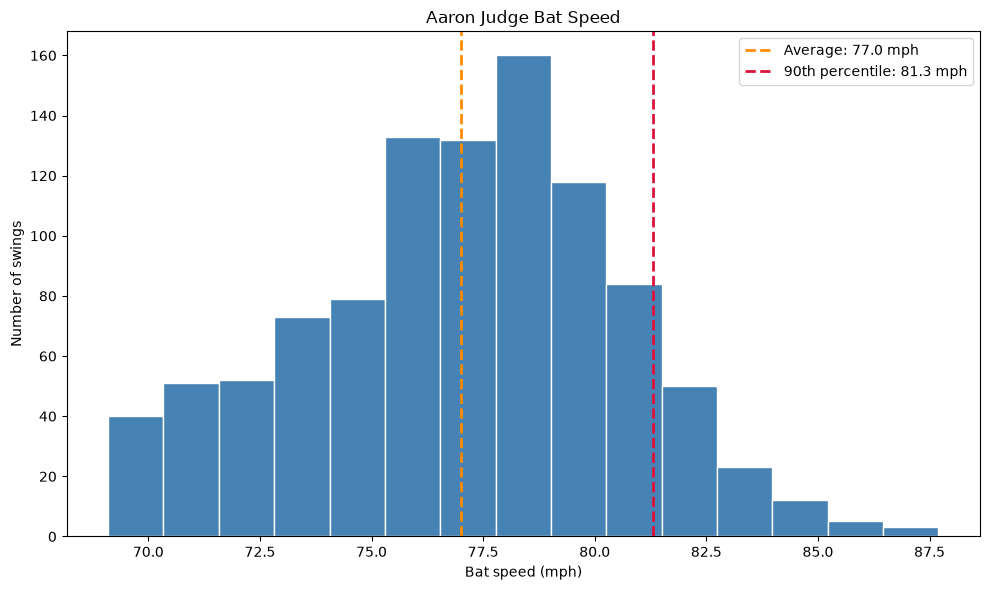

In [6]:
plt.figure(figsize=(10, 6))
plt.hist(bat_speeds, bins=15, color='steelblue', edgecolor='white')
plt.axvline(bat_speeds.mean(), color='darkorange', linestyle='--', linewidth=2, label=f'Average: {bat_speeds.mean():.1f} mph')
plt.axvline(top_10_percent_cutoff, color='crimson', linestyle='--', linewidth=2, label=f'90th percentile: {top_10_percent_cutoff:.1f} mph')
plt.title(f'{player_first} {player_last} Bat Speed')
plt.xlabel('Bat speed (mph)')
plt.ylabel('Number of swings')
plt.legend()
plt.tight_layout()
plt.show()


(The histogram starts near the cutoff because the slowest 10% of swings were removed.)

### 3. Compare Against Hitting Outcomes: Expected Runs

- A swing is any pitch the hitter swung at, including whiffs, fouls, and balls in play. 
- The outcome is `delta_run_exp`, the change in run expectancy from that pitch, as it is the most direct way to measure the outcome and value the swing brings. 
- Positive values help the offense, negative values hurt it. Taking in all swing results, not only batted balls, avoids ignoring whiffs.

In [16]:
# Define what counts as a "swing" (exclude takes: ball, called_strike, etc.)
swing_descriptions = [
    "hit_into_play",
    "foul",
    "foul_tip",
    "swinging_strike",
    "swinging_strike_blocked",
    "missed_bunt",
    "foul_bunt",
]

swings_df = batter_statcast_df[
    batter_statcast_df["description"].isin(swing_descriptions)
].copy()

# Clean up types
swings_df["bat_speed"] = pd.to_numeric(swings_df["bat_speed"], errors="coerce")
swings_df["delta_run_exp"] = pd.to_numeric(swings_df["delta_run_exp"], errors="coerce")

swing_rv = swings_df.dropna(subset=["bat_speed", "delta_run_exp"])

print(f"Total swings: {len(swings_df)}")
print(f"Swings with bat_speed + delta_run_exp: {len(swing_rv)}")

Total swings: 1015
Swings with bat_speed + delta_run_exp: 1015


In [8]:
x = swing_rv["bat_speed"]
y = swing_rv["delta_run_exp"]

speed_fit = linregress(x, y)
print(f"slope: {speed_fit.slope:.5f}")
print(f"R²: {speed_fit.rvalue**2:.4f}")
print(f"p-value: {speed_fit.pvalue:.4f}")
print(f"n: {len(x)}")

slope: 0.00621
R²: 0.0030
p-value: 0.0812
n: 1015


Visualize

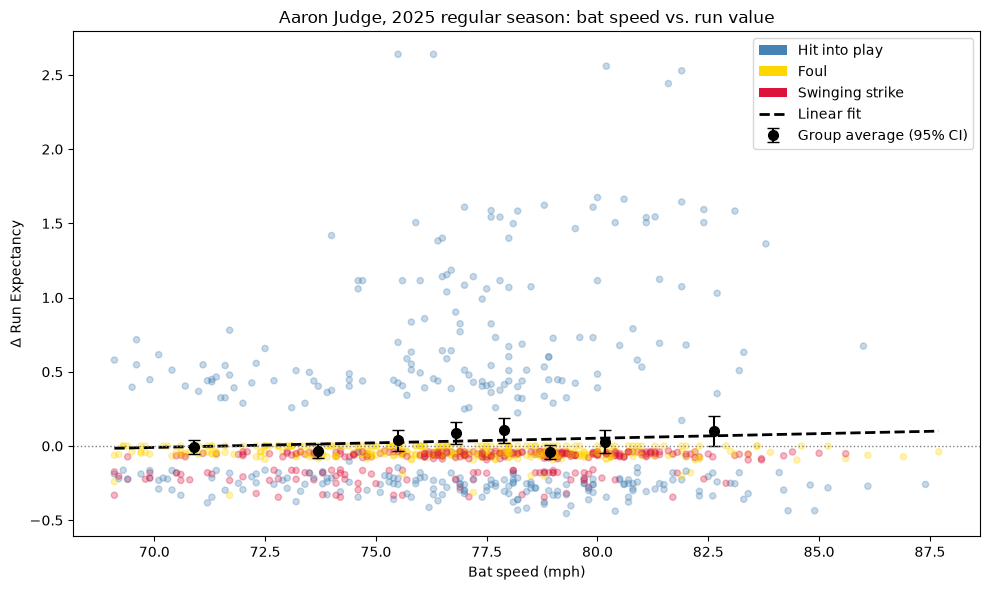

In [9]:
outcome_colors = {
    "hit_into_play": "steelblue",
    "foul": "gold",
    "foul_tip": "gold",
    "foul_bunt": "gold",
    "swinging_strike": "crimson",
    "swinging_strike_blocked": "crimson",
    "missed_bunt": "crimson",
}

colors = swing_rv["description"].map(outcome_colors).fillna("gray")

# Average run value inside 8 bat speed groups
binned = swing_rv.copy()
binned["speed_bin"] = pd.qcut(binned["bat_speed"], q=8, duplicates="drop")
bin_stats = binned.groupby("speed_bin", observed=True).agg(
    mean_speed=("bat_speed", "mean"),
    mean_rv=("delta_run_exp", "mean"),
    sem_rv=("delta_run_exp", "sem"),
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(swing_rv["bat_speed"], swing_rv["delta_run_exp"],
           c=colors, alpha=0.3, s=20)

ax.errorbar(bin_stats["mean_speed"], bin_stats["mean_rv"],
            yerr=1.96 * bin_stats["sem_rv"], fmt="o", color="black",
            capsize=4, markersize=7, label="Group average (95% CI)")

x_fit = np.linspace(swing_rv["bat_speed"].min(), swing_rv["bat_speed"].max(), 200)
ax.plot(x_fit, speed_fit.slope * x_fit + speed_fit.intercept,
        color="black", linewidth=2, linestyle="--", label="Linear fit")

ax.axhline(0, color="gray", linestyle=":", linewidth=1)

outcome_handles = [
    Patch(facecolor="steelblue", label="Hit into play"),
    Patch(facecolor="gold", label="Foul"),
    Patch(facecolor="crimson", label="Swinging strike"),
]
line_handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=outcome_handles + line_handles)

ax.set_title(f"{player_first} {player_last}, 2025 regular season: bat speed vs. run value")
ax.set_xlabel("Bat speed (mph)")
ax.set_ylabel("Δ Run Expectancy")
plt.tight_layout()
plt.show()

### 4. Swing Gain

Generalize the method and find the slope. Scale it to a reasonable scale.
#### Swing Gain (SG): = slope × 2 mph × 100 swings. 

It is the predicted difference in run value per 100 swings between swings 2 mph apart. It describes a pattern in the data and does not prove that swinging harder would cause the change. The 95% confidence interval is scaled the same way. If the whole interval is above zero, the label is "swing harder." If the whole interval is below zero, it is "swing easier." Otherwise it is "no clear signal."



In [17]:
def swing_gain(result, n_swings, mph_change=2, per_swing=100, confidence=0.95):
    """
    Turns a linregress result into Swing Gain (SG).

    SG = expected change in runs per 100 swings if the hitter
    swings mph_change mph harder.
    """
    scale = mph_change * per_swing
    sg = result.slope * scale

    degrees_of_freedom = n_swings - 2
    t_critical = t.ppf(1 - (1 - confidence) / 2, degrees_of_freedom)
    margin = t_critical * result.stderr * scale
    sg_low = sg - margin
    sg_high = sg + margin

    if sg_low > 0:
        recommendation = "swing harder"
    elif sg_high < 0:
        recommendation = "swing easier"
    else:
        recommendation = "no clear signal"

    return {
        "SG": sg,
        "SG_low": sg_low,
        "SG_high": sg_high,
        "recommendation": recommendation,
    }

In [18]:
def analyze_swing_decision(statcast_df, player_id, min_swings=100):
    """
    Computes bat-speed-vs-run-value for one batter.

    Parameters
    ----------
    statcast_df : DataFrame
        Full Statcast pull (must include 'batter', 'bat_speed',
        'delta_run_exp', and 'description' columns).
    player_id : int
        The batter's MLBAM ID.
    min_swings : int
        Minimum number of valid swings after sword-swing removal.

    Returns
    -------
    dict with regression results, or None if the player doesn't
    meet the minimum swing threshold.
    """
    player_id = int(player_id)

    # Get player name
    player_lookup = playerid_reverse_lookup([player_id])

    if not player_lookup.empty:
        player_name = (
            player_lookup.iloc[0]["name_first"]
            + " "
            + player_lookup.iloc[0]["name_last"]
        )
    else:
        player_name = f"Unknown ({player_id})"

    swing_descriptions = [
        "hit_into_play",
        "foul",
        "foul_tip",
        "swinging_strike",
        "swinging_strike_blocked",
        "missed_bunt",
        "foul_bunt",
    ]

    player_df = statcast_df.loc[statcast_df["batter"].eq(player_id)]
    swings_df = player_df.loc[
        player_df["description"].isin(swing_descriptions)
    ].copy()

    swings_df["bat_speed"] = pd.to_numeric(
        swings_df["bat_speed"], errors="coerce"
    )
    swings_df["delta_run_exp"] = pd.to_numeric(
        swings_df["delta_run_exp"], errors="coerce"
    )

    swings_with_speed = swings_df.dropna(subset=["bat_speed"])

    if swings_with_speed.empty:
        return None

    kept, sword_cutoff, n_swords_excluded = remove_sword_swings(swings_with_speed)
    swing_rv = kept.dropna(subset=["delta_run_exp"]).copy()

    if len(swing_rv) < min_swings:
        return None

    x = swing_rv["bat_speed"]
    y = swing_rv["delta_run_exp"]

    result = linregress(x, y)
    sg = swing_gain(result, n_swings=len(swing_rv))


    return {
        "player_name": player_name,
        **sg, 
        "n_swings": len(swing_rv),
        "n_swords_excluded": n_swords_excluded,
        "sword_speed_cutoff": sword_cutoff,
        "mean_bat_speed": x.mean(),
        "mean_delta_run_exp": y.mean(),
        "slope": result.slope,
        "intercept": result.intercept,
        "r_squared": result.rvalue ** 2,
        "p_value": result.pvalue,
    }

### 5. Apply to every yankees hitter

The first table ranks hitters by SG. The second table has the regression details (slope, intercept, R², p value). 

In [ ]:
team = "NYY" #New York Yankees

inning_half = statcast_df["inning_topbot"].astype("string").str.lower()
batting_mask = (
    (statcast_df["home_team"].eq(team) & inning_half.eq("bot"))
    | (statcast_df["away_team"].eq(team) & inning_half.eq("top"))
)

batter_ids = sorted(
    pd.to_numeric(statcast_df.loc[batting_mask, "batter"], errors="coerce")
    .dropna().astype(int).unique()
)
print(f"Found {len(batter_ids)} unique {team} batter IDs in the 2025 data.")

rows = []
for batter_id in batter_ids:
    row = analyze_swing_decision(statcast_df, batter_id)
    if row is not None:
        rows.append(row)

results_df = pd.DataFrame(rows).sort_values("SG", ascending=False).reset_index(drop=True)
print(f"Analyzed {len(results_df)} {team} hitters meeting the swing threshold.")

summary_cols = ["player_name", "SG", "SG_low", "SG_high", "n_swings", "recommendation"]
detail_cols = ["player_name", "slope", "intercept", "r_squared", "p_value",
               "mean_bat_speed", "mean_delta_run_exp",
               "sword_speed_cutoff", "n_swords_excluded"]

summary_table = results_df[summary_cols].round(2)
details_table = results_df[detail_cols].round(4)

Found 20 unique NYY batter IDs in the 2025 data.
Analyzed 19 NYY hitters meeting the swing threshold.


In [14]:
summary_table

,player_name,SG,SG_low,SG_high,n_swings,recommendation
0,giancarlo stanton,3.17,0.32,6.02,445,swing harder
1,jazz chisholm,2.56,1.45,3.68,885,swing harder
2,austin wells,2.21,0.86,3.55,806,swing harder
3,austin slater,1.86,0.21,3.52,288,swing harder
4,jasson domínguez,1.80,0.40,3.19,760,swing harder
5,anthony volpe,1.55,0.47,2.64,978,swing harder
6,cody bellinger,1.44,0.21,2.67,1112,swing harder
7,ryan mcmahon,1.41,0.26,2.56,1009,swing harder
8,aaron judge,1.24,-0.15,2.64,1015,no clear signal
9,dj lemahieu,1.17,-0.52,2.86,192,no clear signal


In [15]:
details_table

,player_name,slope,intercept,r_squared,p_value,mean_bat_speed,mean_delta_run_exp,sword_speed_cutoff,n_swords_excluded
0,giancarlo stanton,0.0158,-1.2614,0.0107,0.0294,80.6712,0.0168,74.34,50
1,jazz chisholm,0.0128,-0.9546,0.0225,0.0000,73.8921,-0.0074,64.43,99
2,austin wells,0.0110,-0.8264,0.0128,0.0013,73.4450,-0.0161,66.15,90
3,austin slater,0.0093,-0.6658,0.0170,0.0271,69.5913,-0.0170,60.08,32
4,jasson domínguez,0.0090,-0.6826,0.0084,0.0117,74.1649,-0.0163,67.84,85
5,anthony volpe,0.0078,-0.5977,0.0080,0.0052,72.5910,-0.0334,62.50,107
6,cody bellinger,0.0072,-0.5097,0.0048,0.0214,70.1817,-0.0039,62.75,124
7,ryan mcmahon,0.0071,-0.5565,0.0057,0.0164,73.9777,-0.0349,66.60,111
8,aaron judge,0.0062,-0.4441,0.0030,0.0812,77.0076,0.0338,69.10,112
9,dj lemahieu,0.0058,-0.4221,0.0097,0.1744,67.5568,-0.0278,58.59,22


### Summary and Conclusion


 - Bat speed is not random. It changes with different count, pitch types, different batting approaches of each day. 
 - There's no absolute rule that shows hitters swinging hard would have better or worse hitting results.
 - Even for batters with a strong coorelation between increasing bat speed and increasing run value, there should be a certain point where the return starts to diminish. Finding that curve and the "sweeet spot of the bat speed" requires a more advanced method than just simple linear regression.  